# Experiment 022: 7B smooth-1000 analysis plots

Analysis of all three smooth 1000-step GRPO arms at 7B. The
registered primary comparison is step 500 against step 1000 within each arm.
Equivalence requires the paired 95% interval to stay inside +-2 percentage
points. A material change requires an absolute difference of at least 2 points
and Holm-adjusted McNemar p below .05 across the three seeds.

The checkpoint grid is 0, 200, 400, 500, 600, 800 and 1000. Step 0 is the
matched SFT model from experiment 013. The comparison between the original 013
endpoint and the smooth run at step 500 is descriptive because their learning
rate schedules are different.


In [1]:
# load the registered summary and all three checkpoint grids
import json
import math
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))

from analysis.stats import _read_preds, align_pred_rows
from data.subjects import tier_of, TIERS

R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '022_1')
os.makedirs(FIGDIR, exist_ok=True)

SEEDS = (0, 1, 2)
GRID = (0, 200, 400, 500, 600, 800, 1000)
GROUPS = ('overall',) + tuple(TIERS)
SEED_COLOURS = {0: '#4c78a8', 1: '#9d0208', 2: '#2a9d8f'}
TIER_COLOURS = {'easy': '#2a9d8f', 'medium': '#f4a261', 'hard': '#d95f59'}


def read_json(path):
    with open(path) as f:
        return json.load(f)


def read_preds(tag, kind='grpo'):
    path = os.path.join(R, tag, f'{kind}_preds.jsonl')
    rows = _read_preds(path)
    assert len(rows) == 1884, f'{path}: expected 1884 rows, found {len(rows)}'
    return rows


def accuracy(rows):
    return sum(r['correct'] for r in rows) / len(rows)


def group_accuracy(rows, group):
    subset = rows if group == 'overall' else [r for r in rows if tier_of(r['subject']) == group]
    return accuracy(subset)


def rolling(values, window=25):
    values = np.asarray(values, dtype=float)
    out = []
    for i in range(len(values)):
        part = values[max(0, i - window + 1):i + 1]
        out.append(float(np.nanmean(part)))
    return np.asarray(out)


def log_series(log, key):
    rows = {int(row['step']): float(row[key]) for row in log if 'step' in row and key in row}
    assert sorted(rows) == list(range(1, 1001)), f'{key}: incomplete training sequence'
    return np.arange(1, 1001), np.asarray([rows[s] for s in range(1, 1001)])


def grid_tag(seed, step):
    return (f'022_smooth_B7_seed{seed}_step1000' if step == 1000
            else f'022_smooth_B7_seed{seed}_step{step}')


summary = read_json(os.path.join(R, '022_comparison_summary.json'))
assert summary['binding'] is True and [int(a['seed']) for a in summary['arms']] == list(SEEDS)
registered = {int(row['seed']): row for row in summary['arms']}

data = {}
for seed in SEEDS:
    root_tag = grid_tag(seed, 1000)
    man = read_json(os.path.join(R, root_tag, 'arm_manifest.json'))
    attempts = [a for a in man.get('attempts', []) if a.get('completed')]
    assert attempts, f'seed {seed}: no completed attempt'
    attempt = attempts[-1]
    assert attempt['end_step'] == 1000 and attempt.get('worker_returncode') in (None, 0)
    assert not attempt.get('cuda_oom') and not attempt.get('resume_blocked')
    assert man['grid'] == list(GRID)

    stages = {}
    sft_tag = f'013_COLAB_FULL_B7_sft_grpo_seed{seed}'
    stages[0] = {
        'gen': read_preds(sft_tag, 'sft'),
        'probe': read_preds(sft_tag, 'sft_logprob'),
        'eval': read_json(os.path.join(R, sft_tag, 'sft_eval.json')),
        'probe_eval': read_json(os.path.join(R, sft_tag, 'sft_logprob.json')),
    }
    for step in GRID[1:]:
        tag = grid_tag(seed, step)
        ev = read_json(os.path.join(R, tag, 'grpo_eval.json'))
        lp = read_json(os.path.join(R, tag, 'grpo_logprob.json'))
        em = read_json(os.path.join(R, tag, 'grpo_eval_manifest.json'))
        assert ev['n_items'] == lp['n_items'] == 1884 and em.get('completed') is True
        stages[step] = {
            'gen': read_preds(tag),
            'probe': read_preds(tag, 'grpo_logprob'),
            'eval': ev,
            'probe_eval': lp,
        }

    original = read_preds(f'013_COLAB_FULL_B7_sft_grpo_seed{seed}')
    data[seed] = {
        'manifest': man,
        'attempt': attempt,
        'trainlog': read_json(os.path.join(R, root_tag, 'grpo_trainlog.json')),
        'curve': read_json(os.path.join(R, root_tag, 'reward_curve.json')),
        'stages': stages,
        'original': original,
    }
    assert abs(accuracy(stages[500]['gen']) - registered[seed]['acc_500']) < 1e-12
    assert abs(accuracy(stages[1000]['gen']) - registered[seed]['acc_1000']) < 1e-12

print('complete grids:', list(data))
print('registered reading:', summary['common_within_run_reading'])
print('probe reading:', summary['common_probe_reading'])
print('figures ->', FIGDIR)


complete grids: [0, 1, 2]
registered reading: no common within-run conclusion, mixed or inconclusive categories, reported arm by arm
probe reading: the probe is unchanged at double budget in all three arms
figures -> ../analysis/figures/022_1


## 1. Run health and training behaviour

Completion checks stay separate from the accuracy result. Every arm must have
1000 logged steps, a successful worker exit and all six post-SFT evaluations
before the registered comparison is used.


In [2]:
# check completion, runtime, memory and finite training values
health_rows = []
for seed in SEEDS:
    d = data[seed]
    log = d['trainlog']
    numeric = []
    for row in log:
        for value in row.values():
            if isinstance(value, (int, float)):
                numeric.append(float(value))
    _, lr = log_series(log, 'learning_rate')
    health_rows.append({
        'seed': seed,
        'completed_steps': d['attempt']['end_step'],
        'runtime_h': d['attempt']['elapsed_sec'] / 3600,
        'peak_vram_gib': d['attempt']['peak_vram_gib'],
        'cuda_oom': bool(d['attempt'].get('cuda_oom', False)),
        'worker_returncode': d['attempt'].get('worker_returncode'),
        'nonfinite_values': sum(not math.isfinite(v) for v in numeric),
        'lr_first': lr[0],
        'lr_last': lr[-1],
        'eval_points': len(d['stages']) - 1,
    })

health_tbl = pd.DataFrame(health_rows)
assert (health_tbl['completed_steps'] == 1000).all()
assert (health_tbl['worker_returncode'].dropna() == 0).all()
assert not health_tbl['cuda_oom'].any()
assert (health_tbl['nonfinite_values'] == 0).all()
assert (health_tbl['eval_points'] == 6).all()
display(health_tbl.round(5))


,seed,completed_steps,runtime_h,peak_vram_gib,cuda_oom,worker_returncode,nonfinite_values,lr_first,lr_last,eval_points
0,0,1000,5.76358,76.43,False,NaN,0,0.00001,0.0,6
1,1,1000,5.55733,67.89,False,0.0,0,0.00001,0.0,6
2,2,1000,4.63839,69.97,False,0.0,0,0.00001,0.0,6


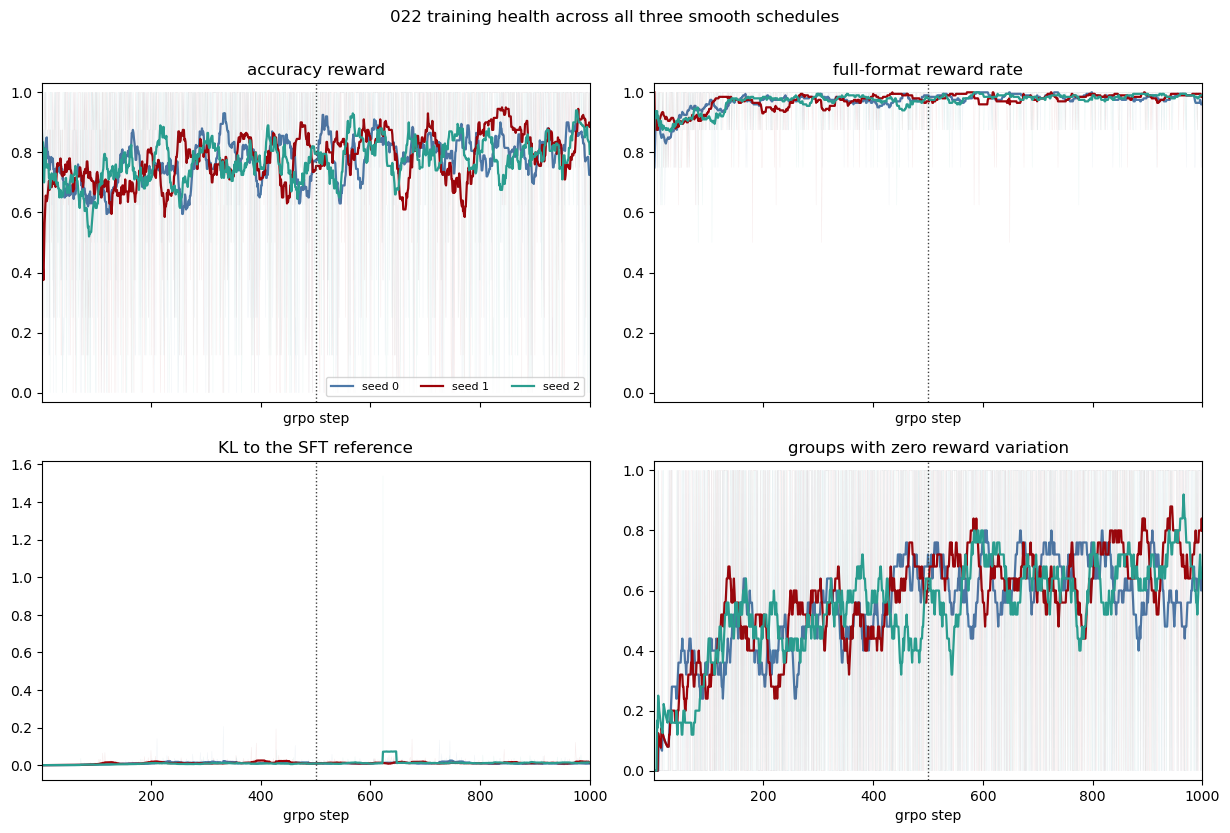

In [3]:
# compare reward and policy diagnostics across all 1000 steps
panels = [
    ('rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
    ('rewards/format_reward/mean', 'full-format reward rate', 0.2),
    ('kl', 'KL to the SFT reference', 1.0),
    ('frac_reward_zero_std', 'groups with zero reward variation', 1.0),
]
fig, axes = plt.subplots(2, 2, figsize=(12.4, 8.2), sharex=True)
for ax, (key, title, divisor) in zip(axes.flat, panels):
    for seed in SEEDS:
        steps, values = log_series(data[seed]['trainlog'], key)
        values = values / divisor
        ax.plot(steps, values, color=SEED_COLOURS[seed], lw=0.35, alpha=0.08)
        ax.plot(steps, rolling(values), color=SEED_COLOURS[seed], lw=1.6,
                label=f'seed {seed}')
    ax.axvline(500, color='0.25', ls=':', lw=1)
    ax.set_title(title)
    ax.set_xlabel('grpo step')
    ax.set_xlim(1, 1000)
axes[0, 0].set_ylim(-0.03, 1.03)
axes[0, 1].set_ylim(-0.03, 1.03)
axes[1, 1].set_ylim(-0.03, 1.03)
axes[0, 0].legend(fontsize=8, ncol=3, loc='lower right')
fig.suptitle('022 training health across all three smooth schedules', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig01_training_health.png'), dpi=200, bbox_inches='tight')
plt.show()


## 2. Accuracy across the registered checkpoint grid

Generative accuracy is primary. The letter probe is diagnostic and is kept on
a separate panel. The vertical line marks the registered step-500 comparison
point, not a checkpoint selected from the observed curve.


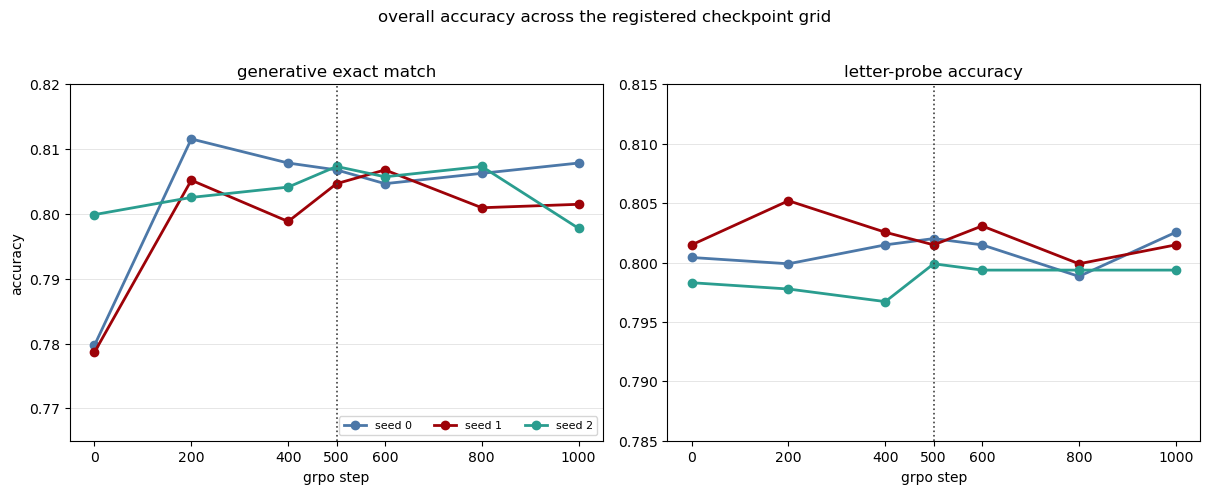

In [4]:
# plot overall generative and probe accuracy at every registered checkpoint
trajectory_rows = []
for seed in SEEDS:
    for step in GRID:
        stage = data[seed]['stages'][step]
        trajectory_rows.append({
            'seed': seed,
            'step': step,
            'generative': accuracy(stage['gen']),
            'probe': accuracy(stage['probe']),
        })
trajectory_tbl = pd.DataFrame(trajectory_rows)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), sharex=True)
for seed in SEEDS:
    rows = trajectory_tbl.query('seed == @seed').sort_values('step')
    axes[0].plot(rows['step'], rows['generative'], marker='o', lw=2,
                 color=SEED_COLOURS[seed], label=f'seed {seed}')
    axes[1].plot(rows['step'], rows['probe'], marker='o', lw=2,
                 color=SEED_COLOURS[seed], label=f'seed {seed}')
for ax in axes:
    ax.axvline(500, color='0.25', ls=':', lw=1.2)
    ax.set_xlabel('grpo step')
    ax.set_xticks(GRID)
    ax.grid(axis='y', color='0.9', lw=0.7)
axes[0].set_ylabel('accuracy')
axes[0].set_title('generative exact match')
axes[1].set_title('letter-probe accuracy')
axes[0].set_ylim(0.765, 0.82)
axes[1].set_ylim(0.785, 0.815)
axes[0].legend(fontsize=8, ncol=3, loc='lower right')
fig.suptitle('overall accuracy across the registered checkpoint grid', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig02_overall_trajectory.png'), dpi=200, bbox_inches='tight')
plt.show()


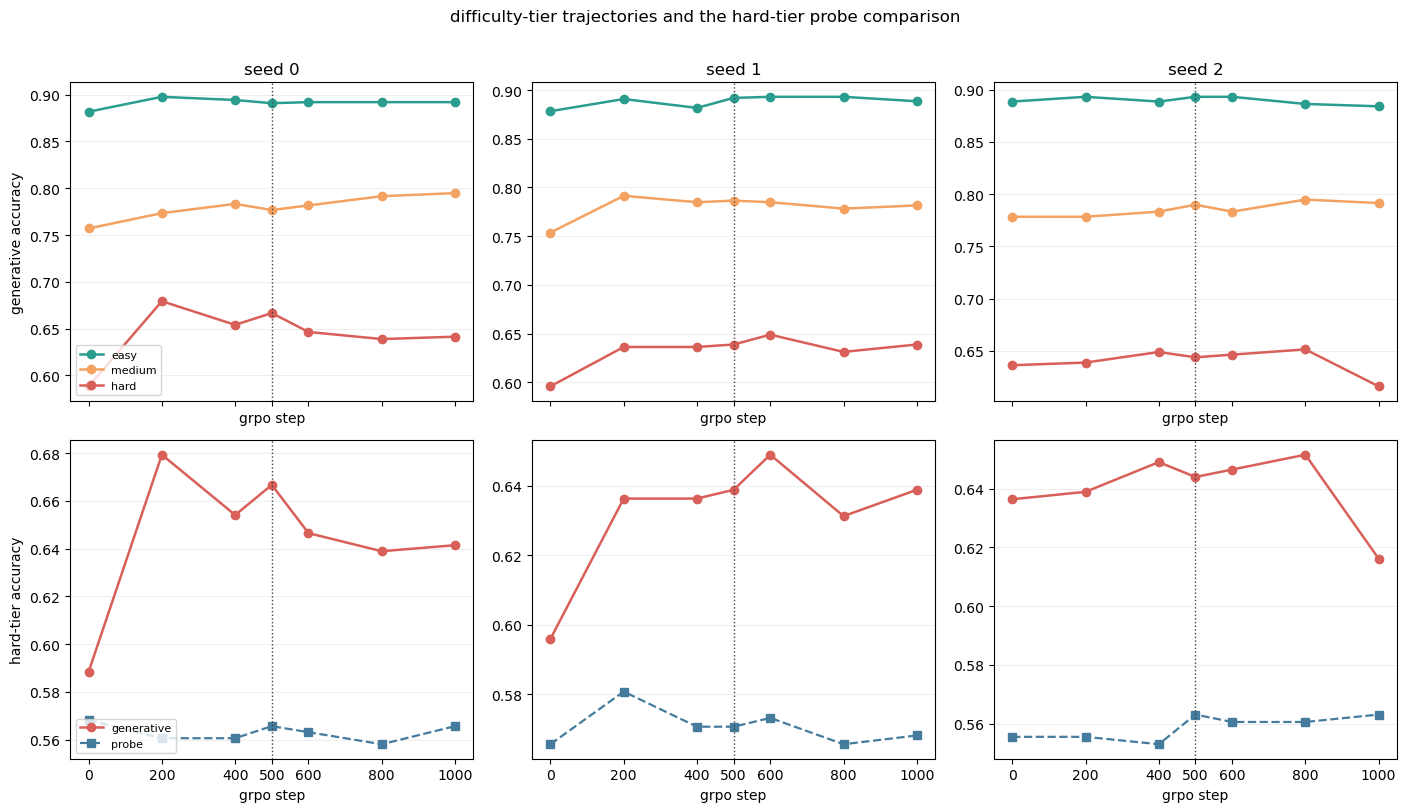

In [5]:
# compare tier trajectories and the hard-tier generative-to-probe margin
tier_rows = []
for seed in SEEDS:
    for step in GRID:
        stage = data[seed]['stages'][step]
        for tier in TIERS:
            tier_rows.append({
                'seed': seed,
                'step': step,
                'tier': tier,
                'generative': group_accuracy(stage['gen'], tier),
                'probe': group_accuracy(stage['probe'], tier),
            })
tier_trajectory_tbl = pd.DataFrame(tier_rows)

fig, axes = plt.subplots(2, 3, figsize=(14.2, 8), sharex=True)
for col, seed in enumerate(SEEDS):
    for tier in TIERS:
        rows = tier_trajectory_tbl.query('seed == @seed and tier == @tier').sort_values('step')
        axes[0, col].plot(rows['step'], rows['generative'], marker='o', lw=1.8,
                          color=TIER_COLOURS[tier], label=tier)
    hard = tier_trajectory_tbl.query('seed == @seed and tier == "hard"').sort_values('step')
    axes[1, col].plot(hard['step'], hard['generative'], marker='o', lw=1.8,
                      color='#d95f59', label='generative')
    axes[1, col].plot(hard['step'], hard['probe'], marker='s', lw=1.6, ls='--',
                      color='#457b9d', label='probe')
    for row in range(2):
        axes[row, col].axvline(500, color='0.25', ls=':', lw=1)
        axes[row, col].set_xticks(GRID)
        axes[row, col].set_xlabel('grpo step')
        axes[row, col].grid(axis='y', color='0.92', lw=0.6)
    axes[0, col].set_title(f'seed {seed}')
axes[0, 0].set_ylabel('generative accuracy')
axes[1, 0].set_ylabel('hard-tier accuracy')
axes[0, 0].legend(fontsize=8, loc='lower left')
axes[1, 0].legend(fontsize=8, loc='lower left')
fig.suptitle('difficulty-tier trajectories and the hard-tier probe comparison', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig03_tier_trajectories.png'), dpi=200, bbox_inches='tight')
plt.show()


## 3. Registered step-500 to step-1000 effects

The generative comparison uses paired test items within each arm. The probe
comparison is against the matched pre-GRPO SFT probe, following the registered
022 rule. These are different contrasts and are labelled separately.


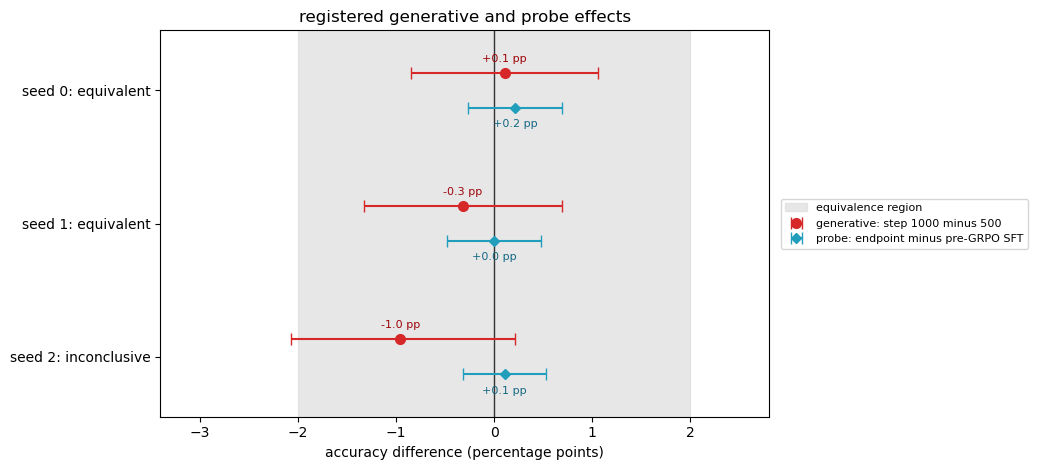

In [6]:
# plot registered paired effects with their confidence intervals
y = np.array([2, 1, 0], dtype=float)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.axvspan(-2, 2, color='0.86', alpha=0.65, label='equivalence region')
ax.axvline(0, color='0.2', lw=1)
effect_rows = []
for row, seed in enumerate(SEEDS):
    st = registered[seed]
    gd = st['within_run_delta'] * 100
    glo, ghi = np.asarray(st['ci']) * 100
    pdiff = st['probe_delta'] * 100
    plo, phi = np.asarray(st['probe_ci']) * 100
    yy = y[row]
    ax.errorbar(gd, yy + 0.13, xerr=[[gd - glo], [ghi - gd]], fmt='o', ms=7,
                capsize=4, color='#d62828', label='generative: step 1000 minus 500' if row == 0 else None)
    ax.errorbar(pdiff, yy - 0.13, xerr=[[pdiff - plo], [phi - pdiff]], fmt='D', ms=5,
                capsize=4, color='#219ebc', label='probe: endpoint minus pre-GRPO SFT' if row == 0 else None)
    ax.annotate(f'{gd:+.1f} pp', (gd, yy + 0.13), xytext=(0, 8),
                textcoords='offset points', ha='center', fontsize=8, color='#9d0208')
    ax.annotate(f'{pdiff:+.1f} pp', (pdiff, yy - 0.13), xytext=(0, -14),
                textcoords='offset points', ha='center', fontsize=8, color='#126782')
    effect_rows.append({
        'seed': seed,
        'gen_delta_pp': gd,
        'gen_ci_low_pp': glo,
        'gen_ci_high_pp': ghi,
        'mcnemar_p_raw': st['p_raw'],
        'mcnemar_p_holm': st['holm_p'],
        'category': st['category'],
        'probe_delta_pp': pdiff,
        'probe_ci_low_pp': plo,
        'probe_ci_high_pp': phi,
        'probe_category': st['probe_class'],
    })
ax.set_yticks(y)
ax.set_yticklabels([f'seed {s}: {registered[s]["category"]}' for s in SEEDS])
ax.set_xlabel('accuracy difference (percentage points)')
ax.set_xlim(-3.4, 2.8)
ax.set_ylim(-0.45, 2.45)
ax.set_title('registered generative and probe effects')
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig04_registered_effects.png'), dpi=200, bbox_inches='tight')
plt.show()

effect_tbl = pd.DataFrame(effect_rows)


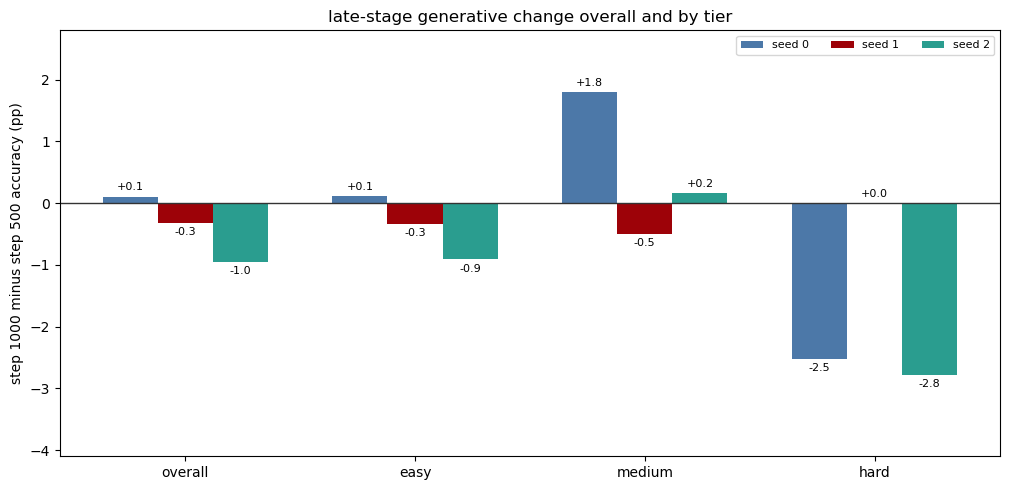

In [7]:
# compare late-stage accuracy changes overall and by difficulty tier
late_rows = []
for seed in SEEDS:
    st = registered[seed]
    late_rows.append({'seed': seed, 'group': 'overall', 'delta_pp': st['within_run_delta'] * 100})
    for tier in TIERS:
        at_1000, at_500 = st['tiers_1000_vs_500'][tier]
        late_rows.append({'seed': seed, 'group': tier, 'delta_pp': (at_1000 - at_500) * 100})
late_tbl = pd.DataFrame(late_rows)

x = np.arange(len(GROUPS))
width = 0.24
fig, ax = plt.subplots(figsize=(10.2, 5))
for offset, seed in zip((-width, 0, width), SEEDS):
    vals = [late_tbl.query('seed == @seed and group == @group')['delta_pp'].iloc[0]
            for group in GROUPS]
    bars = ax.bar(x + offset, vals, width, color=SEED_COLOURS[seed], label=f'seed {seed}')
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in vals], padding=3, fontsize=8)
ax.axhline(0, color='0.2', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(GROUPS)
ax.set_ylabel('step 1000 minus step 500 accuracy (pp)')
ax.set_ylim(-4.1, 2.8)
ax.set_title('late-stage generative change overall and by tier')
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig05_late_tier_effects.png'), dpi=200, bbox_inches='tight')
plt.show()


## 4. Paired answer changes and subject differences

Net accuracy can hide many answer changes in both directions. The transition
plot shows the paired counts, while the subject matrix shows where the late
change was concentrated.


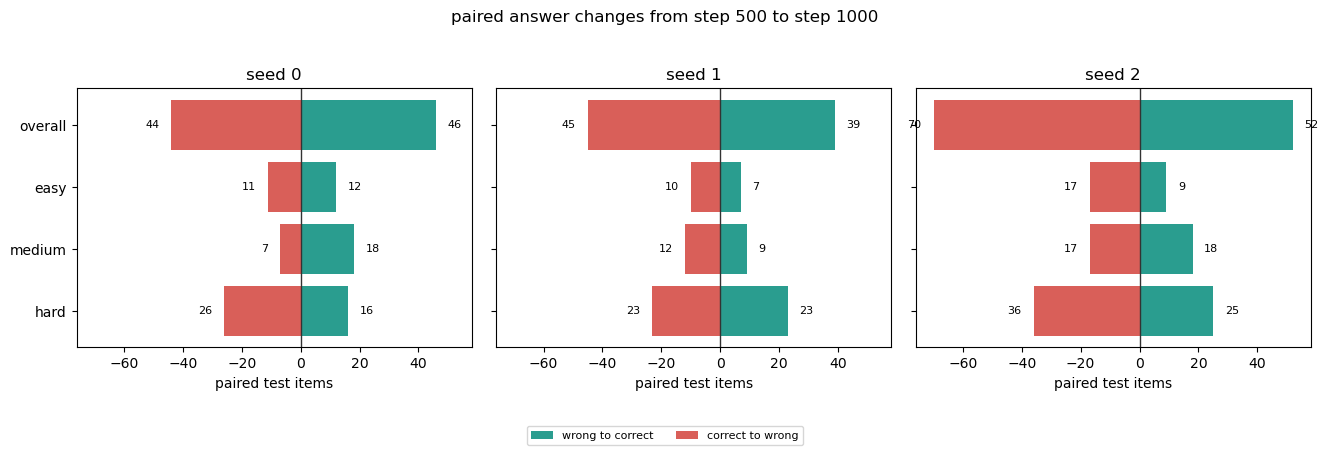

In [8]:
# count wrong-to-correct and correct-to-wrong changes from step 500 to 1000
def transition_counts(old, new):
    old, new = align_pred_rows(old, new)
    gained, lost = [], []
    for group in GROUPS:
        pairs = [(a, b) for a, b in zip(old, new)
                 if group == 'overall' or tier_of(a['subject']) == group]
        gained.append(sum((not a['correct']) and b['correct'] for a, b in pairs))
        lost.append(sum(a['correct'] and (not b['correct']) for a, b in pairs))
    return gained, lost


transition_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.5), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    gained, lost = transition_counts(data[seed]['stages'][500]['gen'],
                                     data[seed]['stages'][1000]['gen'])
    yy = np.arange(len(GROUPS))
    ax.barh(yy, gained, color='#2a9d8f', label='wrong to correct' if seed == 0 else None)
    ax.barh(yy, [-v for v in lost], color='#d95f59', label='correct to wrong' if seed == 0 else None)
    for row, (up, down) in enumerate(zip(gained, lost)):
        ax.text(up + 4, row, str(up), va='center', fontsize=8)
        ax.text(-down - 4, row, str(down), va='center', ha='right', fontsize=8)
        transition_rows.append({'seed': seed, 'group': GROUPS[row],
                                'wrong_to_correct': up, 'correct_to_wrong': down,
                                'net': up - down})
    ax.axvline(0, color='0.2', lw=1)
    ax.set_yticks(yy)
    ax.set_yticklabels(GROUPS)
    ax.set_title(f'seed {seed}')
    ax.set_xlabel('paired test items')
axes[0].invert_yaxis()
fig.legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2)
fig.suptitle('paired answer changes from step 500 to step 1000', y=0.99)
fig.tight_layout(rect=[0, 0.11, 1, 0.96])
fig.savefig(os.path.join(FIGDIR, 'fig06_paired_transitions.png'), dpi=200, bbox_inches='tight')
plt.show()

transition_tbl = pd.DataFrame(transition_rows)


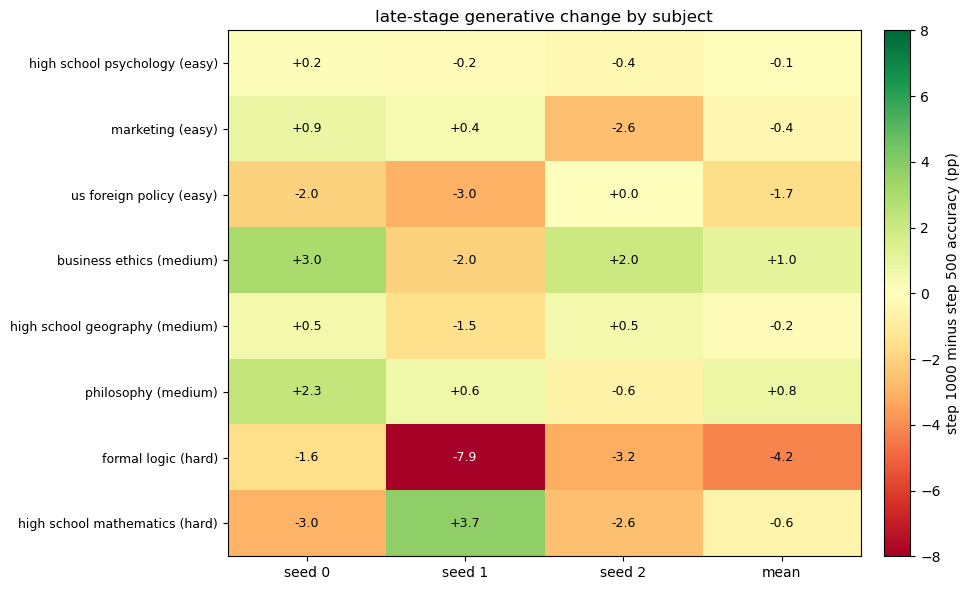

In [9]:
# show subject-level late-stage changes without hiding seed differences
subjects = sorted({r['subject'] for r in data[0]['stages'][500]['gen']},
                  key=lambda s: (list(TIERS).index(tier_of(s)), s))
subject_rows = []
for subject in subjects:
    row = {'subject': subject, 'tier': tier_of(subject)}
    values = []
    for seed in SEEDS:
        old = [r['correct'] for r in data[seed]['stages'][500]['gen'] if r['subject'] == subject]
        new = [r['correct'] for r in data[seed]['stages'][1000]['gen'] if r['subject'] == subject]
        delta = (sum(new) / len(new) - sum(old) / len(old)) * 100
        row[f'seed_{seed}_pp'] = delta
        values.append(delta)
    row['mean_pp'] = float(np.mean(values))
    subject_rows.append(row)
subject_tbl = pd.DataFrame(subject_rows)
matrix = subject_tbl[[f'seed_{s}_pp' for s in SEEDS] + ['mean_pp']].to_numpy()
limit = max(5, float(np.ceil(np.abs(matrix).max())))

fig, ax = plt.subplots(figsize=(10.2, 6))
im = ax.imshow(matrix, cmap='RdYlGn', norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
               aspect='auto', interpolation='nearest')
ax.set_xticks(np.arange(4))
ax.set_xticklabels(['seed 0', 'seed 1', 'seed 2', 'mean'])
ax.set_yticks(np.arange(len(subjects)))
ax.set_yticklabels([f'{s.replace("_", " ")} ({tier_of(s)})' for s in subjects], fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        colour = 'white' if abs(matrix[i, j]) > limit * 0.55 else 'black'
        ax.text(j, i, f'{matrix[i, j]:+.1f}', ha='center', va='center',
                fontsize=9, color=colour)
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label('step 1000 minus step 500 accuracy (pp)')
ax.set_title('late-stage generative change by subject')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig07_subject_effects.png'), dpi=200, bbox_inches='tight')
plt.show()


## 5. Descriptive schedule context and output diagnostics

The original 013 endpoint used a 500-step decay to zero. Step 500 in experiment
022 is only halfway through a 1000-step decay. Their endpoint comparison is
useful context but does not isolate a causal schedule effect.


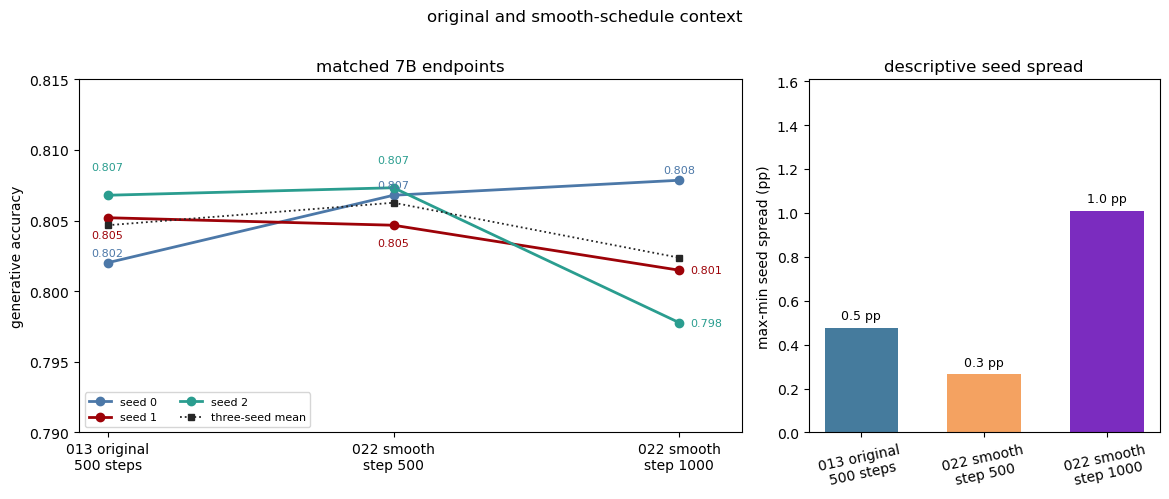

In [10]:
# place the original endpoint beside the smooth step-500 and step-1000 results
context_names = ['013 original\n500 steps', '022 smooth\nstep 500', '022 smooth\nstep 1000']
context = {}
for seed in SEEDS:
    context[seed] = [
        accuracy(data[seed]['original']),
        accuracy(data[seed]['stages'][500]['gen']),
        accuracy(data[seed]['stages'][1000]['gen']),
    ]
means = [np.mean([context[s][i] for s in SEEDS]) for i in range(3)]
spreads = [(max(context[s][i] for s in SEEDS) - min(context[s][i] for s in SEEDS)) * 100
           for i in range(3)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.8, 4.9),
                               gridspec_kw={'width_ratios': [1.7, 0.9]})
for seed in SEEDS:
    ax1.plot(range(3), context[seed], marker='o', lw=2, color=SEED_COLOURS[seed],
             label=f'seed {seed}')
    label_offsets = {0: 5, 1: -15, 2: 18}
    for i, value in enumerate(context[seed]):
        at_last_step = i == len(context[seed]) - 1 and seed in (1, 2)
        offset = (8, 0) if at_last_step else (0, label_offsets[seed])
        ax1.annotate(f'{value:.3f}', (i, value), xytext=offset,
                     textcoords='offset points', ha='left' if at_last_step else 'center',
                     va='center' if at_last_step else 'baseline', fontsize=8,
                     color=SEED_COLOURS[seed])
ax1.plot(range(3), means, marker='s', ms=5, lw=1.3, ls=':', color='0.15',
         label='three-seed mean')
ax1.set_xlim(-0.1, 2.22)
ax1.set_xticks(range(3))
ax1.set_xticklabels(context_names)
ax1.set_ylabel('generative accuracy')
ax1.set_ylim(0.79, 0.815)
ax1.set_title('matched 7B endpoints')
ax1.legend(fontsize=8, ncol=2, loc='lower left')

bars = ax2.bar(context_names, spreads, color=['#457b9d', '#f4a261', '#7b2cbf'], width=0.6)
ax2.bar_label(bars, labels=[f'{v:.1f} pp' for v in spreads], padding=4, fontsize=9)
ax2.set_ylabel('max-min seed spread (pp)')
ax2.set_ylim(0, max(spreads) + 0.6)
ax2.set_title('descriptive seed spread')
ax2.tick_params(axis='x', rotation=12)
fig.suptitle('original and smooth-schedule context', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig08_schedule_context.png'), dpi=200, bbox_inches='tight')
plt.show()

context_tbl = pd.DataFrame([
    {'seed': seed, 'original_013': context[seed][0],
     'smooth_step500': context[seed][1], 'smooth_step1000': context[seed][2],
     'step500_minus_013_pp': (context[seed][1] - context[seed][0]) * 100}
    for seed in SEEDS
])


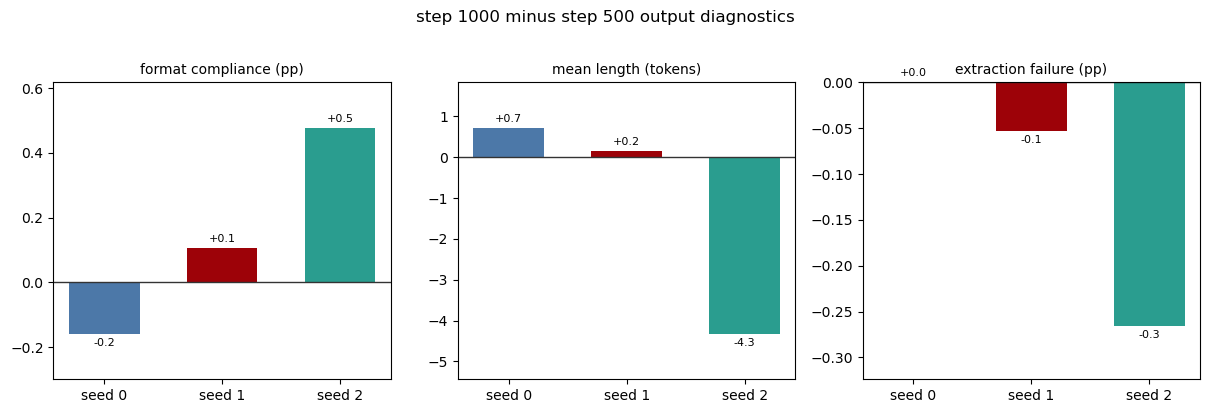

In [11]:
# compare generated-output diagnostics between steps 500 and 1000
diagnostic_rows = []
for seed in SEEDS:
    old = data[seed]['stages'][500]['eval']
    new = data[seed]['stages'][1000]['eval']
    diagnostic_rows.append({
        'seed': seed,
        'format_delta_pp': (new['format_compliance'] - old['format_compliance']) * 100,
        'mean_length_delta': new['mean_len'] - old['mean_len'],
        'extraction_failure_delta_pp': (
            new['extraction_failure_rate'] - old['extraction_failure_rate']) * 100,
    })
diagnostic_tbl = pd.DataFrame(diagnostic_rows)

fig, axes = plt.subplots(1, 3, figsize=(12.2, 4))
for ax, field, title in zip(
        axes,
        ('format_delta_pp', 'mean_length_delta', 'extraction_failure_delta_pp'),
        ('format compliance (pp)', 'mean length (tokens)', 'extraction failure (pp)')):
    vals = diagnostic_tbl[field].to_list()
    bars = ax.bar([f'seed {s}' for s in SEEDS], vals,
                  color=[SEED_COLOURS[s] for s in SEEDS], width=0.6)
    ax.axhline(0, color='0.2', lw=1)
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in vals], padding=3, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.margins(y=0.22)
fig.suptitle('step 1000 minus step 500 output diagnostics', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig09_output_diagnostics.png'), dpi=200, bbox_inches='tight')
plt.show()


## 6. Exact tables


In [12]:
# keep the exact values used by the figures in compact tables
display(health_tbl.round(6))
display(trajectory_tbl.pivot(index='step', columns='seed', values=['generative', 'probe']).round(6))
display(effect_tbl.round(6))
display(late_tbl.pivot(index='group', columns='seed', values='delta_pp').round(3))
display(transition_tbl.set_index(['seed', 'group']))
display(subject_tbl.set_index(['tier', 'subject']).round(3))
display(context_tbl.set_index('seed').round(6))
display(diagnostic_tbl.set_index('seed').round(4))


,seed,completed_steps,runtime_h,peak_vram_gib,cuda_oom,worker_returncode,nonfinite_values,lr_first,lr_last,eval_points
0,0,1000,5.763583,76.43,False,NaN,0,0.00001,0.0,6
1,1,1000,5.557333,67.89,False,0.0,0,0.00001,0.0,6
2,2,1000,4.638389,69.97,False,0.0,0,0.00001,0.0,6


generative                         probe                    
seed          0         1         2         0         1         2
step                                                             
0      0.779724  0.778662  0.799894  0.800425  0.801486  0.798301
200    0.811571  0.805202  0.802548  0.799894  0.805202  0.797771
400    0.807856  0.798832  0.804140  0.801486  0.802548  0.796709
500    0.806794  0.804671  0.807325  0.802017  0.801486  0.799894
600    0.804671  0.806794  0.805732  0.801486  0.803079  0.799363
800    0.806263  0.800955  0.807325  0.798832  0.799894  0.799363
1000   0.807856  0.801486  0.797771  0.802548  0.801486  0.799363

,seed,gen_delta_pp,gen_ci_low_pp,gen_ci_high_pp,mcnemar_p_raw,mcnemar_p_holm,category,probe_delta_pp,probe_ci_low_pp,probe_ci_high_pp,probe_category
0,0,0.106157,-0.849257,1.061571,0.916129,1.000000,equivalent,0.212314,-0.265393,0.690021,unchanged (equivalence rule met)
1,1,-0.318471,-1.326964,0.690021,0.585647,1.000000,equivalent,0.000000,-0.477707,0.477707,unchanged (equivalence rule met)
2,2,-0.955414,-2.070064,0.212314,0.123427,0.370281,inconclusive,0.106157,-0.318471,0.530786,unchanged (equivalence rule met)


seed,0,1,2
group,,,
easy,0.114,-0.341,-0.910
hard,-2.525,0.000,-2.778
medium,1.806,-0.493,0.164
overall,0.106,-0.318,-0.955


wrong_to_correct  correct_to_wrong  net
seed group                                           
0    overall                46                44    2
     easy                   12                11    1
     medium                 18                 7   11
     hard                   16                26  -10
1    overall                39                45   -6
     easy                    7                10   -3
     medium                  9                12   -3
     hard                   23                23    0
2    overall                52                70  -18
     easy                    9                17   -8
     medium                 18                17    1
     hard                   25                36  -11

seed_0_pp  seed_1_pp  seed_2_pp  mean_pp
tier   subject                                                          
easy   high_school_psychology       0.183     -0.183     -0.367   -0.122
       marketing                    0.855      0.427     -2.564   -0.427
       us_foreign_policy           -2.000     -3.000      0.000   -1.667
medium business_ethics              3.000     -2.000      2.000    1.000
       high_school_geography        0.505     -1.515      0.505   -0.168
       philosophy                   2.251      0.643     -0.643    0.750
hard   formal_logic                -1.587     -7.937     -3.175   -4.233
       high_school_mathematics     -2.963      3.704     -2.593   -0.617

,original_013,smooth_step500,smooth_step1000,step500_minus_013_pp
seed,,,,
0,0.802017,0.806794,0.807856,0.477707
1,0.805202,0.804671,0.801486,-0.053079
2,0.806794,0.807325,0.797771,0.053079


,format_delta_pp,mean_length_delta,extraction_failure_delta_pp
seed,,,
0,-0.1592,0.7256,0.0000
1,0.1062,0.1561,-0.0531
2,0.4777,-4.3248,-0.2654


## Cross-referenced conclusion

All three 022 arms completed 1000 GRPO steps on an A100 80GB with BF16. The
training completed normally for every seed, OOM ladder stayed off, no CUDA OOM
or non-finite training value was recorded, and all 18 registered checkpoint pairs
contain complete 1,884-item generative and probe evaluations.

The second 500 steps didn't give one common generative result. Seed 0 changed
by +0.1 pp and seed 1 by -0.3 pp, both equivalent under the registered rule.
Seed 2 changed by -1.0 pp and remained inconclusive because its interval crossed
both the -2 pp boundary and zero. The Holm-adjusted test also did not support a
material decline. The binding result is therefore mixed rather than evidence
that 1000 steps generally improve or reduce the endpoint.

The letter probe stayed equivalent to the pre-GRPO SFT reference in all three
arms. Late hard-tier accuracy fell by 2.5 pp for seed 0, stayed unchanged for
seed 1 and fell by 2.8 pp for seed 2. Most of the overall generative gain was
already present by step 200 to 500, while later checkpoints mainly fluctuated.

Smooth runs at step 500 were within +0.5, -0.1 and +0.1 pp of the matched
013 endpoints. This is descriptive support that both schedules reached similar
mid-budget accuracy, but it's not a causal schedule comparison because the
learning rates at step 500 are different.
